# Week 4 Day 1 — ML Foundations
**Dataset:** Adult Census Income

**Goal:** predict if a person earns more than 50K per year.

## Step 0: Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Upload adult.csv from my computer (Colab shows a "Choose Files" button)
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult.csv


In [3]:
df = pd.read_csv("adult.csv")
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## Task 1: Problem Definition & Metric
- **Target:** `income`
- **Positive class (1):** `>50K`
- **Negative class (0):** `<=50K`

In [4]:
print(df["income"].value_counts())

income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [5]:
# Base rate = percentage of positive class (>50K)
base_rate = (df["income"] == ">50K").mean() * 100
print("Base rate:", round(base_rate, 2), "%")

Base rate: 24.08 %


**Base rate:** about 24% of people earn >50K.

**Business goal:** contact high earners for a premium product, without wasting money on wrong people.

**Metric: F1 score.**
- Precision = how many selected people are really high earners.
- Recall = how many high earners we found.
- Only precision misses customers. Only recall wastes money. F1 balances both.
- Accuracy is not useful, because predicting "nobody earns >50K" already gives 76%.

**In simple words:** About 1 in 4 people earn more than 50K. We want to find as many of them as possible without picking wrong people. We measure this with the F1 score (0 to 1, higher is better).

## Task 2: Data Load & Quick EDA
Missing values are written as `?`. I change them to NaN.

In [6]:
# Count the "?" in each column
print((df == "?").sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [7]:
# Replace "?" with NaN
df = df.replace("?", np.nan)

# Check missing values now
print(df.isnull().sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [8]:
# Make the target column: 1 for >50K, 0 for <=50K
df["target"] = df["income"].map({"<=50K": 0, ">50K": 1})
df[["income", "target"]].head()

,income,target
0,<=50K,0
1,<=50K,0
2,<=50K,0
3,<=50K,0
4,<=50K,0


### Shape and column types

In [9]:
print("Shape:", df.shape)
print()
print(df.dtypes)

Shape: (32561, 16)

age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
target             int64
dtype: object


### Numeric summary

In [10]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,target
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,0.240810
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,0.427581
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


### Value counts

In [11]:
cat_cols = ["workclass", "education", "marital.status", "occupation",
            "relationship", "race", "sex", "native.country"]

for col in cat_cols:
    print(df[col].value_counts().head(5))
    print()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Name: count, dtype: int64

education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
Name: count, dtype: int64

marital.status
Married-civ-spouse    14976
Never-married         10683
Divorced               4443
Separated              1025
Widowed                 993
Name: count, dtype: int64

occupation
Prof-specialty     4140
Craft-repair       4099
Exec-managerial    4066
Adm-clerical       3770
Sales              3650
Name: count, dtype: int64

relationship
Husband          13193
Not-in-family     8305
Own-child         5068
Unmarried         3446
Wife              1568
Name: count, dtype: int64

race
White                 27816
Black                  3124
Asian-Pac-Islander     1039
Amer-Indian-Eskimo      311
Other                   271
Name: count, dtype: int64

sex
Male      21790

### Charts

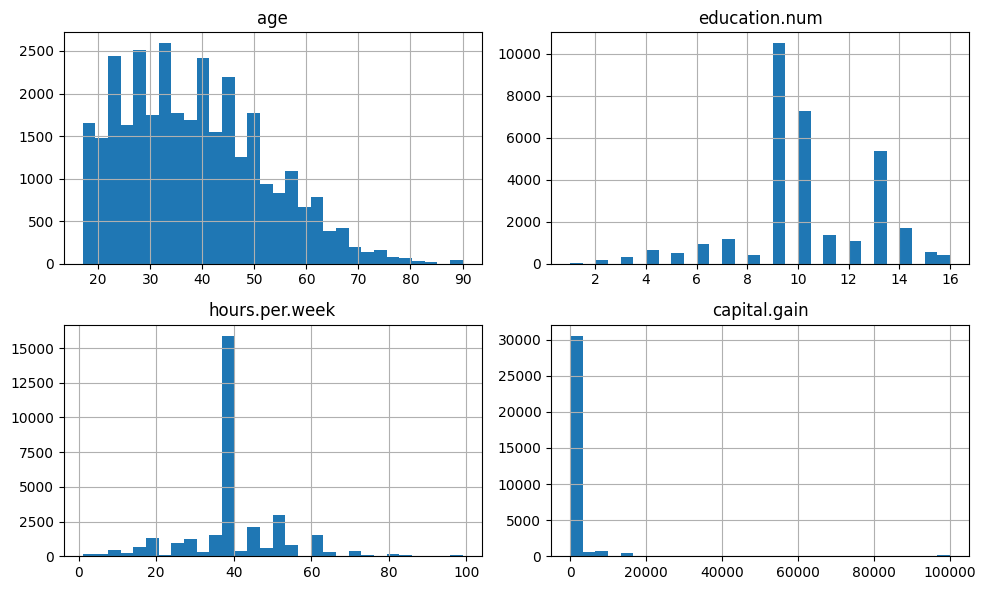

In [12]:
# Histograms of the numeric columns
df[["age", "education.num", "hours.per.week", "capital.gain"]].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

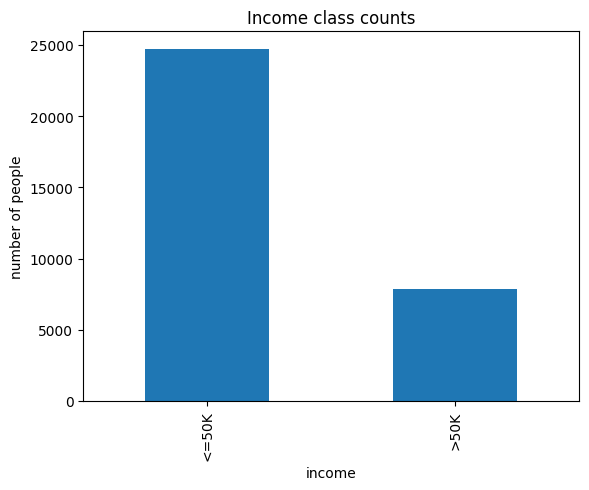

In [13]:
# Bar plot: number of people in each class
df["income"].value_counts().plot(kind="bar", title="Income class counts")
plt.ylabel("number of people")
plt.show()

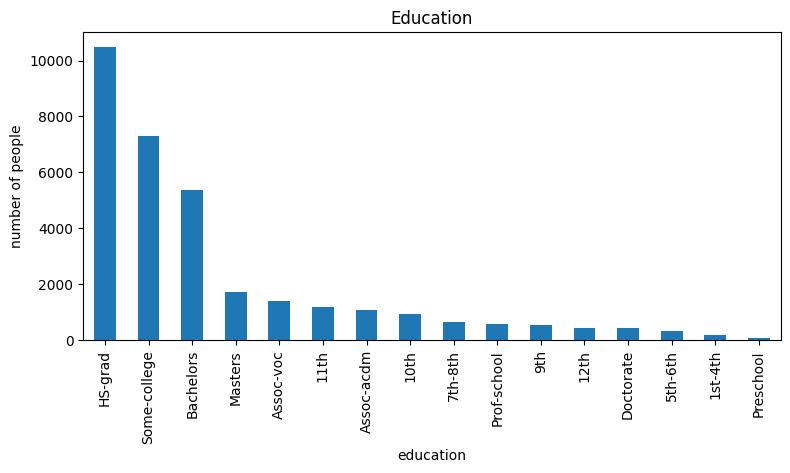

In [14]:
# Bar plot: education
df["education"].value_counts().plot(kind="bar", figsize=(9, 4), title="Education")
plt.ylabel("number of people")
plt.show()

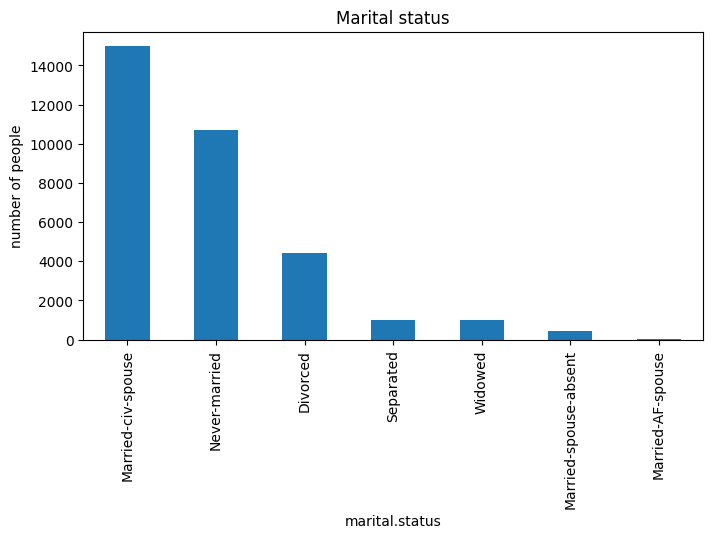

In [15]:
# Bar plot: marital status
df["marital.status"].value_counts().plot(kind="bar", figsize=(8, 4), title="Marital status")
plt.ylabel("number of people")
plt.show()

### Which groups earn more than 50K?

In [16]:
# Percentage of people earning >50K in each education level
print((df.groupby("education")["target"].mean() * 100).round(1).sort_values())

education
Preschool        0.0
1st-4th          3.6
5th-6th          4.8
11th             5.1
9th              5.3
7th-8th          6.2
10th             6.6
12th             7.6
HS-grad         16.0
Some-college    19.0
Assoc-acdm      24.8
Assoc-voc       26.1
Bachelors       41.5
Masters         55.7
Prof-school     73.4
Doctorate       74.1
Name: target, dtype: float64


In [17]:
# Percentage of people earning >50K in each marital status
print((df.groupby("marital.status")["target"].mean() * 100).round(1).sort_values())

marital.status
Never-married             4.6
Separated                 6.4
Married-spouse-absent     8.1
Widowed                   8.6
Divorced                 10.4
Married-AF-spouse        43.5
Married-civ-spouse       44.7
Name: target, dtype: float64


### Summary table

In [18]:
summary = pd.DataFrame({
    "item": [
        "Class: <=50K (negative)",
        "Class: >50K (positive)",
        "Education: Bachelors or higher (education.num >= 13)",
        "Marital status: Married-civ-spouse",
        "Capital gain: more than 0",
        "Hours per week: more than 40",
    ],
    "count": [
        (df["target"] == 0).sum(),
        (df["target"] == 1).sum(),
        (df["education.num"] >= 13).sum(),
        (df["marital.status"] == "Married-civ-spouse").sum(),
        (df["capital.gain"] > 0).sum(),
        (df["hours.per.week"] > 40).sum(),
    ],
})

summary["percent"] = (summary["count"] / len(df) * 100).round(1)
summary.to_csv("eda_summary.csv", index=False)
summary

,item,count,percent
0,Class: <=50K (negative),24720,75.9
1,Class: >50K (positive),7841,24.1
2,Education: Bachelors or higher (education.num ...,8067,24.8
3,Marital status: Married-civ-spouse,14976,46.0
4,Capital gain: more than 0,2712,8.3
5,Hours per week: more than 40,9581,29.4


**What I noticed:**
- 32,561 rows. 24% positive, 76% negative.
- Missing values in `workclass`, `occupation`, `native.country`.
- Higher education = more high earners.
- Married people earn >50K more often.
- `capital.gain` is 0 for most people.

## Task 3: Train / Test Split
I keep 20% of the data as a hold-out test set. `stratify=y` keeps the same class balance and `random_state=42` gives the same split every time.

In [19]:
X = df.drop(columns=["income", "target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 26048
Test rows : 6513


In [20]:
# Check that both parts have the same positive rate
print("Positive rate in train:", round(y_train.mean() * 100, 2), "%")
print("Positive rate in test :", round(y_test.mean() * 100, 2), "%")

Positive rate in train: 24.08 %
Positive rate in test : 24.07 %


**Why a hold-out test set?** It is like a final exam the model has never seen, so it gives an honest score. If I use it for tuning, the model fits that test set and the score looks better than it really is.

## Task 4: Simple Baselines
### Baseline 1: Majority class
Always predict the most common class (`<=50K`).

In [21]:
print("Most common class in train:", y_train.mode()[0])

pred_majority = np.zeros(len(y_test), dtype=int)   # predict 0 for every person

Most common class in train: 0


### Baseline 2: One-feature rule
I check two rules on the training data.

In [22]:
rule1_train = (X_train["education.num"] >= 13).astype(int)
rule2_train = (X_train["capital.gain"] > 0).astype(int)

print("F1 of rule education.num >= 13 :", round(f1_score(y_train, rule1_train), 3))
print("F1 of rule capital.gain > 0    :", round(f1_score(y_train, rule2_train), 3))

F1 of rule education.num >= 13 : 0.488
F1 of rule capital.gain > 0    : 0.32


**My rule:** if `education.num >= 13` (Bachelors or higher), predict >50K.

**Why:** more education usually means higher income, and this rule has a better F1 than the capital gain rule (0.49 vs 0.32).

In [23]:
pred_rule = (X_test["education.num"] >= 13).astype(int)

### Results on the test set
ROC AUC and PR AUC are calculated from the 0/1 predictions.

In [24]:
results = pd.DataFrame({
    "Majority class": [
        accuracy_score(y_test, pred_majority),
        precision_score(y_test, pred_majority, zero_division=0),
        recall_score(y_test, pred_majority),
        f1_score(y_test, pred_majority),
        roc_auc_score(y_test, pred_majority),
        average_precision_score(y_test, pred_majority),
    ],
    "Education rule": [
        accuracy_score(y_test, pred_rule),
        precision_score(y_test, pred_rule),
        recall_score(y_test, pred_rule),
        f1_score(y_test, pred_rule),
        roc_auc_score(y_test, pred_rule),
        average_precision_score(y_test, pred_rule),
    ],
}, index=["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"])

results.round(3)

,Majority class,Education rule
accuracy,0.759,0.758
precision,0.000,0.498
recall,0.000,0.511
f1,0.000,0.505
roc_auc,0.500,0.674
pr_auc,0.241,0.372


[[4945    0]
 [1568    0]]


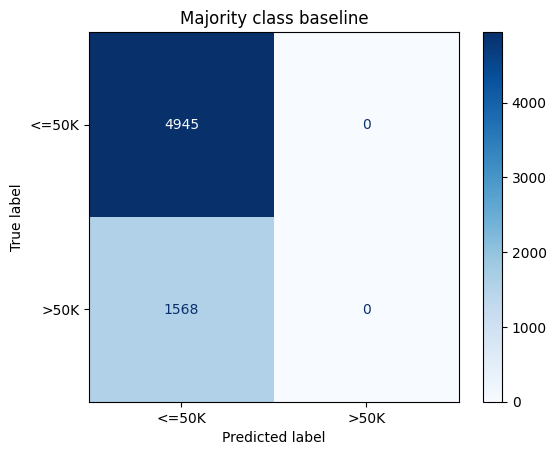

In [25]:
# Confusion matrix: majority class
print(confusion_matrix(y_test, pred_majority))

ConfusionMatrixDisplay.from_predictions(y_test, pred_majority, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Majority class baseline")
plt.show()

[[4136  809]
 [ 766  802]]


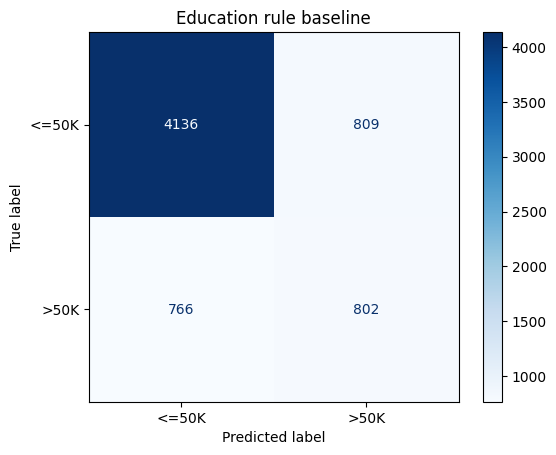

In [26]:
# Confusion matrix: education rule
print(confusion_matrix(y_test, pred_rule))

ConfusionMatrixDisplay.from_predictions(y_test, pred_rule, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Education rule baseline")
plt.show()

**Interpretation:** The education rule wins. The majority baseline has 76% accuracy but F1 = 0, because it never finds a high earner. The education rule has F1 = 0.51. A real model must score clearly more than 0.51 to be useful (my target is 0.60).

## Task 5: Error Analysis
- **False positive:** rule said >50K, but the person earns <=50K.
- **False negative:** rule said <=50K, but the person earns >50K.

In [27]:
test = X_test.copy()
test["actual"] = y_test
test["predicted"] = pred_rule

false_pos = test[(test["predicted"] == 1) & (test["actual"] == 0)]
false_neg = test[(test["predicted"] == 0) & (test["actual"] == 1)]

print("False positives:", len(false_pos))
print("False negatives:", len(false_neg))

False positives: 809
False negatives: 766


In [28]:
cols = ["age", "education", "marital.status", "occupation", "sex", "hours.per.week", "capital.gain"]

# 10 false positives
false_pos[cols].sample(10, random_state=42)

,age,education,marital.status,occupation,sex,hours.per.week,capital.gain
9322,66,Masters,Married-civ-spouse,Sales,Male,50,0
294,45,Bachelors,Married-civ-spouse,Sales,Male,55,0
31442,55,Bachelors,Married-civ-spouse,Prof-specialty,Female,8,0
5973,23,Bachelors,Never-married,NaN,Female,50,0
4309,33,Masters,Married-civ-spouse,Prof-specialty,Male,50,0
17628,55,Bachelors,Widowed,Farming-fishing,Male,40,0
10027,25,Bachelors,Never-married,Tech-support,Male,40,0
17787,24,Bachelors,Never-married,Adm-clerical,Female,20,0
25903,45,Bachelors,Divorced,Exec-managerial,Male,50,0
17673,31,Bachelors,Divorced,Exec-managerial,Female,40,0


In [29]:
# 10 false negatives
false_neg[cols].sample(10, random_state=42)

,age,education,marital.status,occupation,sex,hours.per.week,capital.gain
20372,31,HS-grad,Never-married,Craft-repair,Male,50,0
2466,58,HS-grad,Married-civ-spouse,Exec-managerial,Male,40,7688
18031,32,Some-college,Married-civ-spouse,Sales,Male,40,0
373,45,Assoc-voc,Married-civ-spouse,Sales,Male,50,0
19761,33,Some-college,Married-civ-spouse,Handlers-cleaners,Male,50,0
881,45,Some-college,Married-civ-spouse,Craft-repair,Male,40,0
15931,66,HS-grad,Married-civ-spouse,Adm-clerical,Female,40,0
24703,48,10th,Married-civ-spouse,Transport-moving,Male,40,0
2706,25,HS-grad,Married-civ-spouse,Exec-managerial,Male,84,7298
469,30,HS-grad,Married-civ-spouse,Prof-specialty,Male,15,0


Compare all false positives with all false negatives:

In [30]:
print("Average age        FP:", round(false_pos["age"].mean(), 1), "  FN:", round(false_neg["age"].mean(), 1))
print("Average hours/week FP:", round(false_pos["hours.per.week"].mean(), 1), "  FN:", round(false_neg["hours.per.week"].mean(), 1))

fp_married = (false_pos["marital.status"] == "Married-civ-spouse").mean() * 100
fn_married = (false_neg["marital.status"] == "Married-civ-spouse").mean() * 100
print("Married %          FP:", round(fp_married, 1), "  FN:", round(fn_married, 1))

Average age        FP: 37.7   FN: 45.0
Average hours/week FP: 41.1   FN: 44.7
Married %          FP: 31.8   FN: 88.0


In [31]:
print("Education of false positives:")
print(false_pos["education"].value_counts().head(3))
print()
print("Occupation of false negatives:")
print(false_neg["occupation"].value_counts().head(3))

Education of false positives:
education
Bachelors      633
Masters        124
Prof-school     30
Name: count, dtype: int64

Occupation of false negatives:
occupation
Craft-repair       168
Exec-managerial    141
Sales              105
Name: count, dtype: int64


**Patterns:**
- False positives are younger (about 38) and mostly not married.
- False negatives are older (about 45), mostly married (88%) and work more hours.
- So education alone is not enough. Age, marital status and hours also matter.

**Issues to fix tomorrow:**
1. Fill missing values in `workclass`, `occupation`, `native.country`.
2. Change text columns to numbers (one-hot encoding).
3. Fix the skewed columns `capital.gain` and `capital.loss`.
4. Drop `education` (same as `education.num`).
5. Drop `fnlwgt` (not useful).

**Primary metric:** F1 score. The majority baseline has 76% accuracy but F1 = 0, so accuracy cannot be trusted. The education rule has F1 = 0.51, so this is the score to beat. My target for the week is F1 of 0.60 or more.